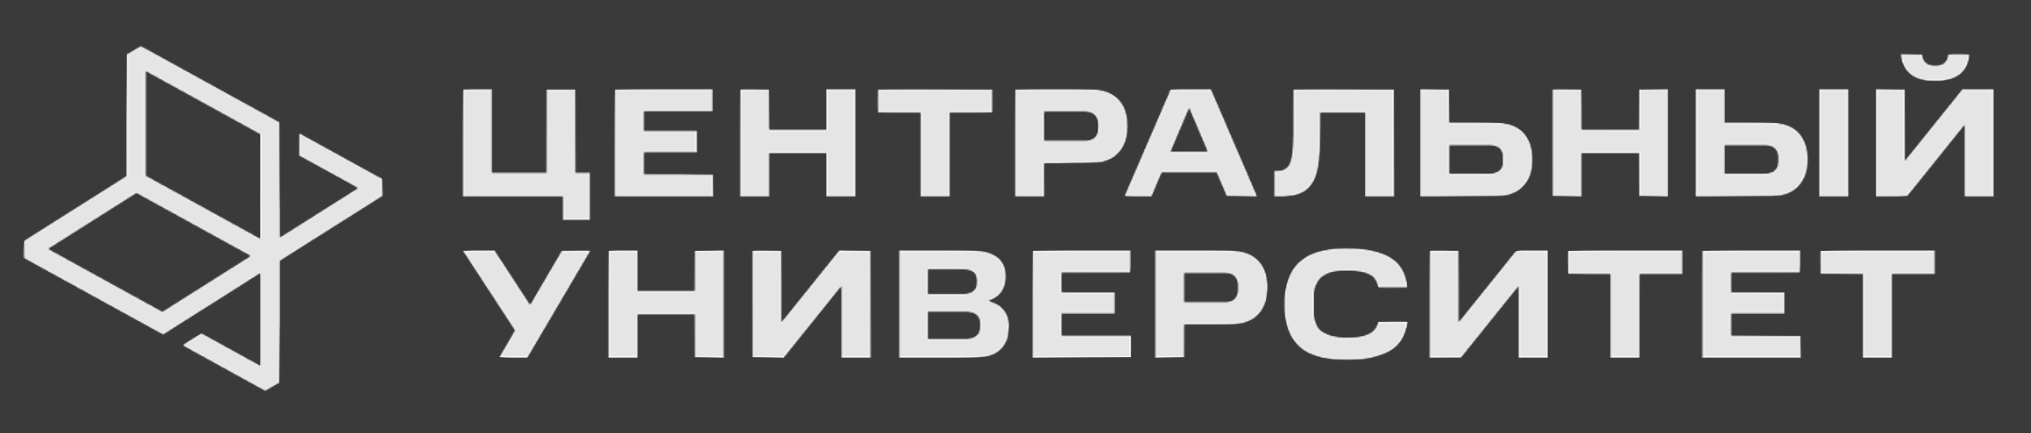

## Семинар 2. Использование Albumentations в задаче классификации

Этот пример показывает, как использовать Albumentations для классификации изображений. Мы будем использовать набор данных [`Cats vs Dogs`](https://www.kaggle.com/shaunthesheep/microsoft-catsvsdogs-dataset). Задача состоит в том, чтобы определить, содержит ли изображение кошку или собаку.

### Импорт необходимых библиотек

In [3]:
!pip3 install albumentations

import torch.backends.cudnn as cudnn
import torchvision.models   as models
import matplotlib.pyplot    as plt
import albumentations       as A
import torch.nn as nn

import torch.optim
import random
import shutil
import torch
import copy
import cv2
import os

from albumentations.pytorch import ToTensorV2
from torch.utils.data       import Dataset, DataLoader
from collections            import defaultdict
from urllib.request         import urlretrieve

from tqdm import tqdm

cudnn.benchmark = True

random.seed(42)

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 369 kB 2.6 MB/s eta 0:00:01
     |████████████████████████████████| 48.3 MB 1.9 MB/s eta 0:00:01    |██                              | 3.2 MB 3.0 MB/s eta 0:00:15     |████                            | 5.9 MB 2.2 MB/s eta 0:00:19     |█████▋                          | 8.5 MB 1.8 MB/s eta 0:00:23     |███████                         | 10.4 MB 1.1 MB/s eta 0:00:34     |███████                         | 10.6 MB 459 kB/s eta 0:01:23     |███████████████▍                | 23.2 MB 1.0 MB/s eta 0:00:25     |█████████████████▎              | 26.1 MB 2.7 MB/s eta 0:00:09     |█████████████████▊              | 26.8 MB 2.7 MB/s eta 0:00:08     |███████████████████▊            | 29.8 MB 4.4 MB/s eta 0:00:05     |█████████████████████▌          | 32.4 MB 1.8 MB/s eta 0:00:09     |█████████████████████▉          | 33.0 MB 1.8 MB/s eta 0:00:09     |███████████████████████         | 34

/Users/d.churikov/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/d.churikov/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Установим корневой каталог для загруженного набора данных.

In [4]:
dataset_directory = os.path.join(os.environ["HOME"], "datasets/cats-vs-dogs")

### Загрузим и извлечём набор данных `Cats vs Dogs`.

In [6]:
!pip3 install kagglehub
import kagglehub

dataset_path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print("Path to dataset files:", dataset_path)

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 68 kB 1.8 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


100%|██████████| 775M/775M [02:27<00:00, 5.50MB/s] 

Extracting files...


Path to dataset files: /Users/d.churikov/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1


### Разделим файлы из набора данных на обучающий и проверочный наборы.

Некоторые файлы в наборе данных не работают, поэтому мы будем использовать только те файлы изображений, которые OpenCV смог корректно загрузить. Мы будем использовать 20 000 изображений для обучения, 4936 изображений для проверки и 10 изображений для тестирования.

In [7]:
root_directory = os.path.join(dataset_path, "PetImages")

cat_directory = os.path.join(root_directory, "Cat")
dog_directory = os.path.join(root_directory, "Dog")

cat_images_filepaths = sorted([os.path.join(cat_directory, f) for f in os.listdir(cat_directory)])
dog_images_filepaths = sorted([os.path.join(dog_directory, f) for f in os.listdir(dog_directory)])
images_filepaths = [*cat_images_filepaths, *dog_images_filepaths]

correct_images_filepaths = [i for i in images_filepaths if cv2.imread(i) is not None]

random.shuffle(correct_images_filepaths)

train_images_filepaths = correct_images_filepaths[:20000]
val_images_filepaths   = correct_images_filepaths[20000:-10]
test_images_filepaths  = correct_images_filepaths[-10:]

print(len(train_images_filepaths), len(val_images_filepaths), len(test_images_filepaths))

Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Corrupt JPEG data: 214 extraneous bytes before marker 0xd9
Corrupt JPEG data: 128 extraneous bytes before marker 0xd9
Corrupt JPEG data: 99 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1153 extraneous bytes before marker 0xd9
Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 162 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9
Corrupt JPEG data: 254 extraneous bytes before marker 0xd9
Corrupt JPEG data: 2230 extraneous bytes before marker 0xd9
Corrupt JPEG data: 65 extraneous bytes before marker 0xd9


20000 4987 10


### Определим функцию для визуализации изображений и их меток.

Определим функцию, которая будет принимать список путей к файлам изображений и их меток и визуализировать их в виде сетки. Правильные метки окрашены в зелёный цвет, а неверно предсказанные — в красный.

In [ ]:
def display_image_grid(images_filepaths, predicted_labels=(), cols=5):
    rows = len(images_filepaths) // cols
    figure, ax = plt.subplots(nrows=rows, ncols=cols, figsize=(12, 6))
    for i, image_filepath in enumerate(images_filepaths):
        image = cv2.imread(image_filepath)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        true_label = os.path.normpath(image_filepath).split(os.sep)[-2]
        predicted_label = predicted_labels[i] if predicted_labels else true_label
        color = "green" if true_label == predicted_label else "red"
        ax.ravel()[i].imshow(image)
        ax.ravel()[i].set_title(predicted_label, color=color)
        ax.ravel()[i].set_axis_off()
    plt.tight_layout()
    plt.show()

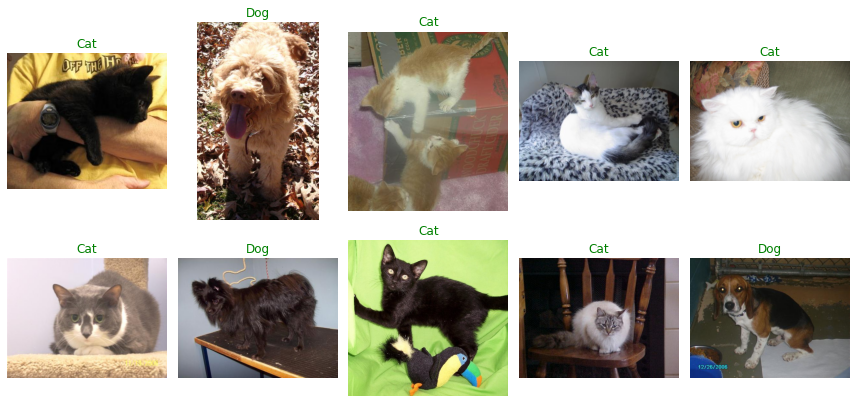

In [ ]:
display_image_grid(test_images_filepaths)

### Определим класс набора данных PyTorch.

Далее мы определим набор данных PyTorch. Если ты новичок в работе с наборами данных PyTorch, обратись к этому руководству: https://pytorch.org/tutorials/beginner/data_loading_tutorial.html.
Наша задача — бинарная классификация: модель должна предсказать, содержит ли изображение кошку или собаку. Наши метки будут обозначать вероятность того, что изображение содержит кошку. Таким образом, правильная метка для изображения с кошкой будет равна 1.0, а правильная метка для изображения с собакой будет равна 0.0.
__init__ получает необязательный аргумент transform. Это функция преобразования конвейера расширения Albumentations. Затем в __getitem__ класс Dataset будет использовать эту функцию для дополнения изображения и возвращать его вместе с правильной меткой.

In [ ]:
class CatsVsDogsDataset(Dataset):
    def __init__(self, images_filepaths, transform=None):
        self.images_filepaths = images_filepaths
        self.transform = transform

    def __len__(self):
        return len(self.images_filepaths)

    def __getitem__(self, idx):
        image_filepath = self.images_filepaths[idx]

        # your code here (⊃｡•́‿•̀｡)⊃
        image = cv2.imread(image_filepath)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if os.path.normpath(image_filepath).split(os.sep)[-2] == "Cat":
            label = 1.0
        else:
            label = 0.0
        if self.transform is not None:
            image = self.transform(image=image)["image"]
        return image, label

### Используем Albumentations для определения функций преобразования для наборов данных обучения и проверки.

Мы используем Albumentations для реализации конвейера обработки входных изображений, увеличения обучающих и валидационных наборов данных.
В обоих конвейерах мы сначала изменяем размер входного изображения, чтобы его наименьший размер составлял `160px`, а затем делаем кадрирование $128{\times}128$.
Для тренировочного набора данных мы также применяем дополнения к этому кадру.
Далее мы нормализуем изображение.
Сначала мы разделим все значения пикселей изображения на $255$, так что значение каждого пикселя будет лежать в диапазоне $[0.0, 1.0]$.
Затем мы вычтем средние значения пикселей `mean` и разделим значения на стандартное отклонение `std`.
Среднее значение и стандартное отклонение взяты из набора данных `ImageNet`.
Тем не менее они достаточно хорошо переносятся на набор данных «Cats vs Dogs».

После этого мы применим ToTensorV2, который преобразует массив NumPy в тензор PyTorch, он послужит входом для нейронной сети.

Обрати внимание, что в конвейере проверки мы будем использовать `A.CenterCrop` вместо `A.RandomCrop`, потому что мы хотим, чтобы результаты проверки были детерминированными и не зависели от случайного расположения культур.

In [ ]:
train_transform = A.Compose(
    [
        A.SmallestMaxSize(max_size=160),
        A.RandomCrop(height=128, width=128),
        # your code here (⊃｡•́‿•̀｡)⊃
        A.RandomBrightnessContrast(p=0.5),
        A.ChannelShuffle(p=0.1),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ]
)
train_dataset = CatsVsDogsDataset(images_filepaths=train_images_filepaths, transform=train_transform)

In [ ]:
val_transform = A.Compose(
    [
        A.SmallestMaxSize(max_size=160),
        A.CenterCrop(height=128, width=128),
        # your code here (⊃｡•́‿•̀｡)⊃
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ]
)
val_dataset = CatsVsDogsDataset(images_filepaths=val_images_filepaths, transform=val_transform)

Также определим функцию, которая берёт набор данных и визуализирует различные аугментации, применённые к одному и тому же изображению.

In [ ]:
def visualize_augmentations(dataset, idx=0, samples=10, cols=5):
    dataset = copy.deepcopy(dataset)
    dataset.transform = A.Compose([t for t in dataset.transform if not isinstance(t, (A.Normalize, ToTensorV2))])
    rows = samples // cols
    figure, ax = plt.subplots(nrows=rows, ncols=cols, figsize=(12, 6))
    for i in range(samples):
        image, _ = dataset[idx]
        ax.ravel()[i].imshow(image)
        ax.ravel()[i].set_axis_off()
    plt.tight_layout()
    plt.show()

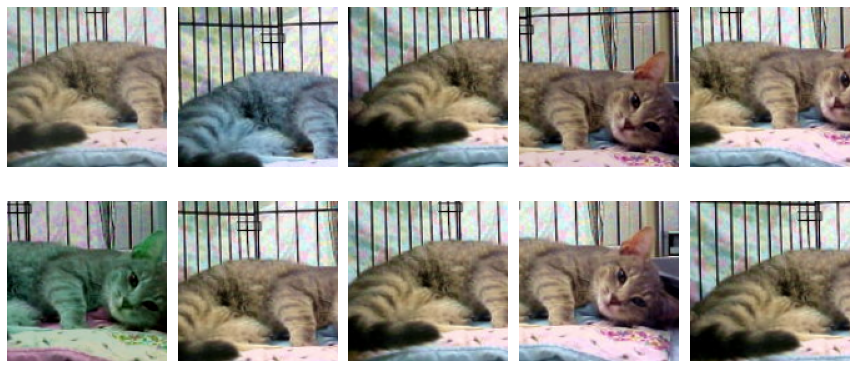

In [ ]:
random.seed(42)
visualize_augmentations(train_dataset)

### Определим дополнительные функции полезные для обучения.

Мы определим несколько помощников для нашего обучающего конвейера. `calculate_accuracy` берёт предсказания модели и истинные метки и возвращает точность для этих предсказаний.
`MetricMonitor` помогает отслеживать метрики, такие как точность или потери во время обучения и валидации.

In [ ]:
def calculate_accuracy(output, target):
    output = torch.sigmoid(output) >= 0.5
    target = target == 1.0
    return torch.true_divide((target == output).sum(dim=0), output.size(0)).item()

In [ ]:
class MetricMonitor:
    def __init__(self, float_precision=3):
        self.float_precision = float_precision
        self.reset()

    def reset(self):
        self.metrics = defaultdict(lambda: {"val": 0, "count": 0, "avg": 0})

    def update(self, metric_name, val):
        metric = self.metrics[metric_name]

        metric["val"] += val
        metric["count"] += 1
        metric["avg"] = metric["val"] / metric["count"]

    def __str__(self):
        return " | ".join(
            [
                "{metric_name}: {avg:.{float_precision}f}".format(
                    metric_name=metric_name, avg=metric["avg"], float_precision=self.float_precision
                )
                for (metric_name, metric) in self.metrics.items()
            ]
        )

### Определим параметры обучения.

Здесь мы определяем несколько параметров обучения, такие как архитектура модели, скорость обучения, размер пакета данных, число  эпох и т. д.

In [ ]:
params = {
 "model": "resnet18",
 "device": "cuda",
 "lr": 0.001,
 "batch_size": 64,
 "num_workers": 8,
 "epochs": 5,
}

### Создаём все необходимые объекты и функции для обучения и проверки.

In [ ]:
model = getattr(models, params["model"])(weights=None, num_classes=1,)
model = model.to(params["device"])
criterion = nn.BCEWithLogitsLoss().to(params["device"])
optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"])

In [ ]:
train_loader = DataLoader(
    train_dataset, batch_size=params["batch_size"], shuffle=True, num_workers=params["num_workers"], pin_memory=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=params["batch_size"], shuffle=False, num_workers=params["num_workers"], pin_memory=True,
)

In [ ]:
def train(train_loader, model, criterion, optimizer, epoch, params):
    metric_monitor = MetricMonitor()
    model.train()
    stream = tqdm(train_loader)
    for i, (images, target) in enumerate(stream, start=1):
        images = images.to(params["device"], non_blocking=True)
        target = target.to(params["device"], non_blocking=True).float().view(-1, 1)
        output = model(images)
        loss = criterion(output, target)
        accuracy = calculate_accuracy(output, target)
        metric_monitor.update("Loss", loss.item())
        metric_monitor.update("Accuracy", accuracy)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        stream.set_description(
            "Epoch: {epoch}. Train.      {metric_monitor}".format(epoch=epoch, metric_monitor=metric_monitor)
        )

In [ ]:
def validate(val_loader, model, criterion, epoch, params):
    metric_monitor = MetricMonitor()
    model.eval()
    stream = tqdm(val_loader)
    with torch.no_grad():
        for i, (images, target) in enumerate(stream, start=1):
            images = images.to(params["device"], non_blocking=True)
            target = target.to(params["device"], non_blocking=True).float().view(-1, 1)
            output = model(images)
            loss = criterion(output, target)
            accuracy = calculate_accuracy(output, target)

            metric_monitor.update("Loss", loss.item())
            metric_monitor.update("Accuracy", accuracy)
            stream.set_description(
                "Epoch: {epoch}. Validation. {metric_monitor}".format(epoch=epoch, metric_monitor=metric_monitor)
            )

### Тренируем модель.

In [ ]:
for epoch in range(1, params["epochs"] + 1):
    train(train_loader, model, criterion, optimizer, epoch, params)
    validate(val_loader, model, criterion, epoch, params)

Epoch: 1. Train.      Loss: 0.695 | Accuracy: 0.596:  27%|██████████████████████████████▏                                                                                   | 83/313 [00:05<00:14, 16.21it/s]Corrupt JPEG data: 226 extraneous bytes before marker 0xd9
Epoch: 1. Train.      Loss: 0.692 | Accuracy: 0.597:  30%|██████████████████████████████████▌                                                                               | 95/313 [00:06<00:13, 15.74it/s]Corrupt JPEG data: 399 extraneous bytes before marker 0xd9
Epoch: 1. Train.      Loss: 0.677 | Accuracy: 0.604:  46%|████████████████████████████████████████████████████▎                                                            | 145/313 [00:09<00:10, 15.81it/s]Corrupt JPEG data: 239 extraneous bytes before marker 0xd9
Epoch: 1. Train.      Loss: 0.676 | Accuracy: 0.604:  47%|█████████████████████████████████████████████████████                                                            | 147/313 [00:09<00:10, 15.66it/s]Cor

### Предсказываем метки для изображений и визуализируем эти предсказания.

Теперь у нас есть обученная модель, поэтому давай попробуем предсказать метки для некоторых изображений и посмотрим, насколько эти предсказания верны. Сначала мы создадим набор данных PyTorch `CatsVsDogsInferenceDataset`. Его код аналогичен тренировочному и проверочному наборам данных, но набор Inference Dataset возвращает только изображение, а не связанную с ним метку, поскольку в реальном мире у нас обычно нет доступа к истинным меткам и мы хотим вывести их с помощью нашей обученной модели.

In [ ]:
class CatsVsDogsInferenceDataset(Dataset):
    def __init__(self, images_filepaths, transform=None):
        self.images_filepaths = images_filepaths
        self.transform = transform

    def __len__(self):
        return len(self.images_filepaths)

    def __getitem__(self, idx):
        image_filepath = self.images_filepaths[idx]
        image = cv2.imread(image_filepath)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform is not None:
            image = self.transform(image=image)["image"]
        return image

test_transform = A.Compose(
    [
        A.SmallestMaxSize(max_size=160),
        A.CenterCrop(height=128, width=128),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ]
)
test_dataset = CatsVsDogsInferenceDataset(images_filepaths=test_images_filepaths, transform=test_transform)
test_loader = DataLoader(
    test_dataset, batch_size=params["batch_size"], shuffle=False, num_workers=params["num_workers"], pin_memory=True,
)

In [ ]:
model = model.eval()
predicted_labels = []
with torch.no_grad():
    for images in test_loader:
        images = images.to(params["device"], non_blocking=True)
        output = model(images)
        predictions = (torch.sigmoid(output) >= 0.5)[:, 0].cpu().numpy()
        predicted_labels += ["Cat" if is_cat else "Dog" for is_cat in predictions]

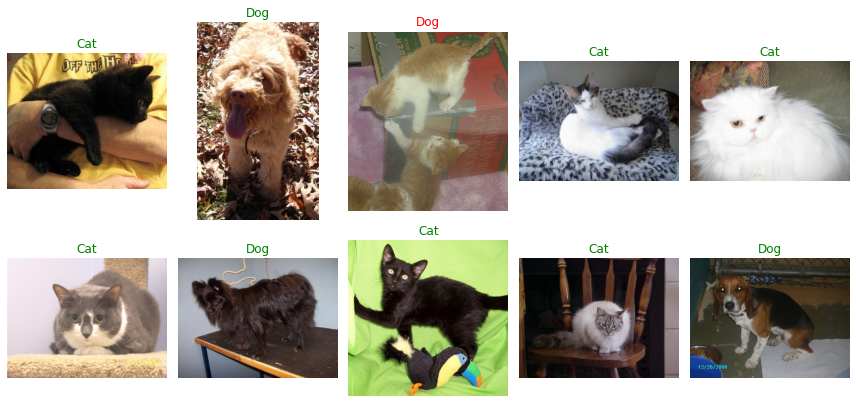

In [ ]:
display_image_grid(test_images_filepaths, predicted_labels)

Как мы видим, наша модель предсказала правильные метки для 9 из 10 изображений. Если ты обучишь модель на большее количество эпох, ты получишь лучшие результаты.


## Бонус. Использовать аугментацию или нет?!

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Training without data augmentation:
Epoch 1/20 - Loss: 1.6507, Accuracy: 0.3933, Val Loss: 1.3144, Val Accuracy: 0.5280
Epoch 2/20 - Loss: 1.2906, Accuracy: 0.5333, Val Loss: 1.0962, Val Accuracy: 0.6085
Epoch 3/20 - Loss: 1.1169, Accuracy: 0.6024, Val Loss: 0.9698, Val Accuracy: 0.6549
Epoch 4/20 - Loss: 0.9965, Accuracy: 0.6480, Val Loss: 0.9053, Val Accuracy: 0.6809
Epoch 5/20 - Loss: 0.9040, Accuracy: 0.6824, Val Loss: 0.8605, Val Accuracy: 0.6960
Epoch 6/20 - Loss: 0.8267, Accuracy: 0.7109, Val Loss: 0.8079, Val Accuracy: 0.7189
Epoch 7/20 - Loss: 0.7751, Accuracy: 0.7282, Val Loss: 0.7963, Val Accuracy: 0.7286
Epoch 8/20 - Loss: 0.7215, Accuracy: 0.7465, Val Loss: 0.7658, Val Accuracy: 0.7384
Epoch 9/20 - Loss: 0.6783, Accuracy: 0.7640, Val Loss: 0.7609, Val Accuracy: 0.7385
Epoch 10/20 - Loss: 0.6373, Accuracy: 0.7755, Val Loss: 0.7566, Val Accuracy: 0.7423
Epoch 11/

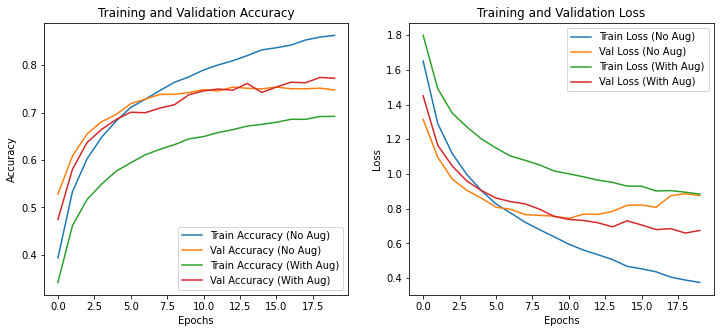

In [ ]:
import torchvision.transforms as transforms
import matplotlib.pyplot      as plt
import albumentations         as A
import torch.optim            as optim
import torch.nn               as nn
import numpy                  as np

import torch

from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import CIFAR10

# Define a basic CNN model
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc1   = nn.Linear(128 * 4 * 4, 256)
        self.fc2   = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = x.view(-1, 128*4*4)
        x = self.dropout(torch.relu(self.fc1(x)))
        x = self.fc2(x)

        return x

# Define Albumentations augmentations
augmentations = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.GaussianBlur(p=0.1),
    A.ColorJitter(p=0.2),
    A.CoarseDropout(max_holes=1, max_height=8, max_width=8, fill_value=0, p=0.5),
    ToTensorV2()
])

# Dataset class with Albumentations
class CIFAR10Dataset(Dataset):
    def __init__(self, train=True, transform=None):
        self.data = CIFAR10(root='./data', train=train, download=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image, label = self.data[idx]
        image = ( np.array(image) / 255 ).astype(np.float32)

        if self.transform:
            image = self.transform(image=image)["image"]
        else:
            image = transforms.ToTensor()(image)

        return image, label

# Load data with and without augmentation
train_dataset_no_aug = CIFAR10Dataset(train=True, transform=ToTensorV2())
train_dataset_aug    = CIFAR10Dataset(train=True, transform=augmentations)
test_dataset         = CIFAR10(root='./data', train=False, transform=transforms.ToTensor(), download=True)

train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=64, shuffle=True )
train_loader_aug    = DataLoader(train_dataset_aug   , batch_size=64, shuffle=True )
test_loader         = DataLoader(test_dataset        , batch_size=64, shuffle=False)

# Training function
def train_model(model, train_loader, epochs=30, use_augmentation=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    for epoch in range(epochs):
        model.train()
        total_train_loss, total_correct = 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_correct += (predicted == labels).sum().item()

        avg_train_loss = total_train_loss / len(train_loader)
        train_accuracy = total_correct    / len(train_loader.dataset)
        val_loss, val_accuracy = validate_model(model, test_loader)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'  ].append(val_loss      )
        history['train_acc' ].append(train_accuracy)
        history['val_acc'   ].append(val_accuracy  )

        print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_train_loss:.4f}, Accuracy: {train_accuracy:.4f}, "
              f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}")
    return history

# Validation function
def validate_model(model, test_loader):
    model.eval()
    total_correct = 0
    total_val_loss = 0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_correct += (predicted == labels).sum().item()

    avg_val_loss = total_val_loss / len(test_loader)
    val_accuracy = total_correct / len(test_loader.dataset)
    return avg_val_loss, val_accuracy

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Train and evaluate model without augmentation
model_no_aug = SimpleCNN().to(device)
print("Training without data augmentation:")
history_no_aug = train_model(model_no_aug, train_loader_no_aug, epochs=20)

# Train and evaluate model with augmentation
model_aug = SimpleCNN().to(device)
print("\nTraining with data augmentation:")
history_aug = train_model(model_aug, train_loader_aug, epochs=20)

# Plotting results
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_no_aug['train_acc'], label='Train Accuracy (No Aug)')
plt.plot(history_no_aug['val_acc'  ], label='Val Accuracy (No Aug)')
plt.plot(history_aug   ['train_acc'], label='Train Accuracy (With Aug)')
plt.plot(history_aug   ['val_acc'  ], label='Val Accuracy (With Aug)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_no_aug['train_loss'], label='Train Loss (No Aug)'  )
plt.plot(history_no_aug['val_loss'  ], label='Val Loss (No Aug)'    )
plt.plot(history_aug   ['train_loss'], label='Train Loss (With Aug)')
plt.plot(history_aug   ['val_loss'  ], label='Val Loss (With Aug)'  )
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

plt.show()